# Experiment: FHIF-inspired (LOOSE)

LOOSE VERSION of FHIF (Zuo et al., 2023; 3.63 m at 5 s in HLTP++'s table), known only as 'feature-level hierarchical interaction fusion'. Our interpretation: three levels of features (the target alone, each target-neighbour pair, the neighbour group) fused bottom-up with learned gates, then a unimodal LSTM decoder.

Part of the model comparison in `experiments/MODEL_ALTERNATIVES.md`. Run All; set `DEBUG = False` in section 2 for the real run.

## 0. Decisions & assumptions

Every choice that could change the result is listed here; the cell notes below repeat the ones that apply to each cell.

**Shared by every notebook (S)**

| # | Decision / assumption | Why | Departure from paper / alternative |
|---|---|---|---|
| S1 | Same data for every model: NGSIM us-101 + i-80 (DEBUG: first 250k rows of us-101), scene-level 70/10/20 split, seed 42, train-only normalization. | Differences in the results must come from the model, not the data. | Papers use their own splits, so published numbers are not like-for-like with ours. |
| S2 | Same training budget for every model: config.py defaults (12 epochs, Adam lr 5e-4 decayed x0.6 per epoch, batch 128, weight decay 1e-5, grad clip 1.0). | A fair comparison; per-model tuning would favour whichever model got tuned most. | Each paper's own schedule (e.g. CS-LSTM trains longer with lr 1e-3). Tune later with --mode tune if a model looks under-trained. |
| S3 | Loss = MSE + bivariate-Gaussian NLL + neighbour-goal MSE (`basic_loss`); the risk-scaled loss is used only where this notebook's M table says so (STRAP-R-based variants). Models without a goal head output zero goals, so their goal term is a constant. A model may add its own `aux_loss` (only the diffusion model does). | Keeps one training objective; the risk-scaled loss is STRAP-R's own contribution. | Loss values are therefore not comparable across models: compare RMSE only. |
| S4 | Best checkpoint = lowest validation loss (`fit` default); test RMSE is reported at 1-5 s for that checkpoint. | Same selection rule for every model. | Selecting on val RMSE would be closer to the reported metric. |
| S5 | KNOWN LIMITATION (not fixed): positions are relative to the target at each timestep, so the target's own history is always (0, 0) and lateral speed is always 0 (NGSIM gives longitudinal speed only). The target is seen through speed, acceleration and lane features; lateral context comes from neighbours. | Kept as is (user decision) so every model gets identical inputs. | Papers feed the target's own x/y track; lane-change prediction is handicapped for all models here. |
| S6 | Neighbours = up to 15 risk-selected vehicles (S/O-field > RISK_THRESHOLD), not every nearby vehicle. | Same scene construction as STRAP. | Grid/graph papers use all vehicles in range; ours see only the risk-selected ones. |
| S7 | Output = one bivariate Gaussian per future step (mu_x, mu_y, sigma_x, sigma_y, rho); RMSE uses the mean. Multimodal models are moment-matched to one Gaussian. | The `fit` / `evaluate_trajectory` contract and how STRAP's Table I is scored. | minADE/minFDE over modes would favour multimodal models. |

**Specific to this model (M)**

| # | Decision / assumption | Why | Departure from paper / alternative |
|---|---|---|---|
| M1 | LOOSE VERSION: not enough public detail to reproduce this model; the architecture below is our interpretation of its title/abstract. Results do NOT represent the published model. | User asked for best-effort versions of thin-detail models. | Treat as an extra baseline, not as a reproduction. |
| M2 | Levels: individual = target LSTM state; pairwise = MLP(target, neighbour, relative position) per neighbour; group = attention pooling of the pairwise features. | A three-level hierarchy is the natural reading of the name. | - |
| M3 | Fusion: g1 = sigmoid gate mixing individual with group; g2 gates that result with the strongest pair (max-pool); unimodal decoder LSTM(128). | Feature-level gated fusion. | - |

## 1. Setup

**Decisions in this cell:** seed fixed to `SEED` (42) in every notebook so initialisation is not a source of differences (S1).

In [1]:
import sys
from pathlib import Path

# Repo root = first folder upwards that contains src/ (works from experiments/ or the root).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import time
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from src.config import (
    BATCH_SIZE, BETA_LOSS, DEBUG_MAX_ROWS, DEVICE, DROPOUT, DT, LEARNING_RATE, LR_DECAY, N_V,
    NGSIM_LOCATIONS, NUM_EPOCHS, NORMALIZATION_FILE, SEED, STATE_DIM, TF_STEPS, TH_STEPS, WEIGHT_DECAY,
)
from src.data.loader import NGSIMDataLoader, create_dataloader
from src.data.normalization import load_stats, normalize_samples
from src.evaluation.evaluate import evaluate_trajectory
from src.models.strap import STRAP
from src.pipeline import collision_scores, metric_rows, test_groups
from src.train import fit, prepare_data
from experiments.benchmark import compare, save_result

torch.manual_seed(SEED)
print("device:", DEVICE)

/home/st_students/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


device: cuda


## 2. Experiment config

**Decisions in this cell:** training budget is config.py's (S2); `use_risk_loss` as in the M table; collisions scored at 2 m like `--mode collisions`.

In [2]:
EXP_NAME = "fhif"          # unique per notebook -> experiments/results/<EXP_NAME>.json
DESCRIPTION = "LOOSE: individual / pairwise / group interaction features fused hierarchically with gates"

DEBUG = False                  # True: DEBUG_MAX_ROWS of us-101 for a quick check; False: full data
LOCATIONS = ["us-101"] if DEBUG else NGSIM_LOCATIONS

HPARAMS = dict(               # keyword args of src.train.fit
    num_epochs=NUM_EPOCHS,
    use_risk_loss=False,       # False = basic loss (STRAP-B style)
    beta=BETA_LOSS,
    learning_rate=LEARNING_RATE,
    batch_size=BATCH_SIZE,
    lr_decay=LR_DECAY,
    weight_decay=WEIGHT_DECAY,
)

RUN_COLLISIONS = False         # per-pair collision scoring on the test split (slow on full data)
COLLISION_THRESHOLD = 2.0     # metres, GT collision label distance

CKPT_DIR = ROOT / "experiments" / "checkpoints" / EXP_NAME

## 3. Data
Train-only normalization stats and the intention codebook are written to `CKPT_DIR`.

**Decisions in this cell:** same loader, split and train-only normalization as every other notebook (S1, S6); `norm_stats` is loaded here so the model (next section) can recover metres and lane numbers.

In [3]:
loader = NGSIMDataLoader(locations=LOCATIONS, max_rows=DEBUG_MAX_ROWS if DEBUG else None)
train_s, val_s, centers = prepare_data(loader, save_dir=str(CKPT_DIR))
_, _, test_raw = loader.get_splits()   # cached; raw (unnormalized) test split
# Train-only mean/std; models that need metres or lane numbers undo the normalization with it.
norm_stats = load_stats(str(CKPT_DIR / NORMALIZATION_FILE))
print(f"train/val/test = {len(train_s)}/{len(val_s)}/{len(test_raw)}")

2026-10-29 12:37:19,651 - STRAP - INFO - [NGSIMLoader] Loading cached data from /home/st_students/MTP/data/raw/ngsim/ngsim_us-101.csv


2026-10-29 12:37:27,022 - STRAP - INFO - [NGSIMLoader] Dropping 704,000 duplicate rows (0 duplicate groups differ in other columns)


2026-10-29 12:37:27,816 - STRAP - INFO - [NGSIMLoader] 'us-101' period 1: 1,180,598 rows, frame_id offset=0


2026-10-29 12:37:27,842 - STRAP - INFO - [NGSIMLoader] 'us-101' period 2: 1,403,095 rows, frame_id offset=9609


2026-10-29 12:37:27,869 - STRAP - INFO - [NGSIMLoader] 'us-101' period 3: 1,515,240 rows, frame_id offset=19680


...

2026-10-29 12:55:08,275 - STRAP - INFO - [Train] Fitting k-means intention codebook on training data...


/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


2026-10-29 12:55:38,006 - STRAP - INFO - [Train] Saved intention codebook ((100, 4)) to /home/st_students/MTP/experiments/checkpoints/fhif/intention_clusters.pkl


2026-10-29 12:55:39,625 - STRAP - INFO - [NGSIMLoader] Per-recording temporal split over 6 recordings: train=540149 {'i-80': 287507, 'us-101': 252642}, val=86077 {'i-80': 50059, 'us-101': 36018}, test=121130 {'i-80': 58995, 'us-101': 62135}


train/val/test = 540149/86077/121130


## 4. Model

Any `torch.nn.Module` works if `forward(states, mask, dims)` returns a 3-tuple:

| output | shape | meaning |
|---|---|---|
| `traj_dist` | `(B, T_f=50, 5)` | `[mu_x, mu_y, sigma_x, sigma_y, rho]` of the target, metres relative to its last observed position (x longitudinal, y lateral); `sigma > 0`, `rho` in (-1, 1) |
| `goals` | `(B, N-1, 4)` | neighbour goals; a model without a goal head returns `states.new_zeros(B, N - 1, 4)` |
| third | anything | ignored by training/eval (STRAP returns its risk field) |

Inputs: `states (B, T_h=30, N, 11)` normalized (vehicle 0 = target, rest neighbours, zero-padded),
`mask (B, N)` True = real vehicle, `dims (B, N, 2)` raw length/width in metres.
Feature index: 0 rel-longitudinal m, 1 rel-lateral m, 2 speed/30, 3 lateral speed (always 0), 4 accel/10,
5 type/2, 6 relative lane (target - vehicle, left = +), 7 length/10, 8 width/3, 9 S-field risk, 10 O-field risk.
Raw value = `states * std + mean` with `norm_stats`. STRAP's k-means codebook is only loaded if the model has a `risk_decoder`.

**Decisions in this cell:** three interaction levels (M2), gated hierarchical fusion (M3). Built after the data cell because it needs `norm_stats`.

In [4]:
def gaussian(out):
    """Raw (..., 5) -> valid [mu_x, mu_y, sigma_x, sigma_y, rho] (S7)."""
    return torch.cat([out[..., :2], F.softplus(out[..., 2:4]) + 1e-3, torch.tanh(out[..., 4:5])], dim=-1)

class VehicleEncoder(nn.Module):
    """Shared per-vehicle encoder: FC + leaky ReLU + LSTM over the 30 history steps."""
    def __init__(self, input_dim=STATE_DIM, emb=32, d=64):
        super().__init__()
        self.embed = nn.Linear(input_dim, emb)
        self.lstm = nn.LSTM(emb, d, batch_first=True)

    def forward(self, x):                                           # x (B, T, N, F)
        B, T, N, D_in = x.shape
        seq, (h, _) = self.lstm(F.leaky_relu(self.embed(x.transpose(1, 2).reshape(B * N, T, D_in)), 0.1))
        return seq.reshape(B, N, T, -1), h[-1].reshape(B, N, -1)   # per-step and last-step encodings

class FHIF(nn.Module):
    def __init__(self, norm_stats, d=64, heads=4, dec=128, T_f=TF_STEPS):
        super().__init__()
        self.register_buffer("mean", torch.tensor(norm_stats["mean"]))
        self.register_buffer("std", torch.tensor(norm_stats["std"]))
        self.T_f = T_f
        self.encoder = VehicleEncoder(STATE_DIM, 32, d)
        self.pair = nn.Sequential(nn.Linear(2 * d + 2, d), nn.ReLU(), nn.Linear(d, d))
        self.group = nn.MultiheadAttention(d, heads, batch_first=True)
        self.g1, self.g2 = nn.Linear(2 * d, d), nn.Linear(2 * d, d)
        self.decoder = nn.LSTM(d, dec, batch_first=True)
        self.out = nn.Linear(dec, 5)

    def forward(self, states, mask, dims=None):
        B, _, N, _ = states.shape
        _, h = self.encoder(states)
        pos = states[:, -1, :, :2] * self.std[:2] + self.mean[:2]
        target = h[:, 0]
        pairs = self.pair(torch.cat([target[:, None].expand(-1, N, -1), h, pos / 30.0], -1))   # (B, N, d)
        nbr = mask.clone()
        nbr[:, 0] = True                                            # the target's own pair keeps attention valid
        grp, _ = self.group(target[:, None], pairs, pairs, key_padding_mask=~nbr)
        g = torch.sigmoid(self.g1(torch.cat([target, grp[:, 0]], -1)))
        level2 = g * target + (1 - g) * grp[:, 0]
        strongest = pairs.masked_fill(~nbr[..., None], float("-inf")).amax(1)
        g = torch.sigmoid(self.g2(torch.cat([level2, strongest], -1)))
        ctx = g * level2 + (1 - g) * strongest
        out, _ = self.decoder(ctx[:, None].expand(-1, self.T_f, -1))
        return gaussian(self.out(out)), states.new_zeros(B, N - 1, 4), None


def build_model():
    return FHIF(norm_stats)

model = build_model().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"{type(model).__name__}: {n_params:,} parameters")

FHIF: 171,141 parameters


## 5. Train

**Decisions in this cell:** `fit` with the config budget (S2); best checkpoint by val loss (S4). Loss curves are only comparable within this notebook (S3).

2026-10-29 12:55:40,459 - STRAP - INFO - Training STRAP on cuda


2026-10-29 12:55:40,460 - STRAP - INFO - Epochs: 12, Risk Loss: False, Beta: 0.0, LR: 0.0005, Batch: 128, LR decay: 0.6, Weight decay: 1e-05


2026-10-29 12:55:40,461 - STRAP - INFO - Number of training batches: 4220


2026-10-29 12:55:40,461 - STRAP - INFO - Number of validation batches: 673


2026-10-29 12:56:39,998 - STRAP - INFO - Epoch 1/12: Train Loss=661.6745 (goal=598.7877, traj=62.8868), Val Loss=394.8667, Val RMSE=2.7135


...

2026-10-29 13:05:12,865 - STRAP - INFO - Epoch 10/12: Train Loss=605.1914 (goal=598.7868, traj=6.4045), Val Loss=391.4365, Val RMSE=2.1115


2026-10-29 13:06:09,174 - STRAP - INFO - Epoch 11/12: Train Loss=605.1830 (goal=598.7889, traj=6.3941), Val Loss=391.3868, Val RMSE=2.1019


2026-10-29 13:07:10,620 - STRAP - INFO - Epoch 12/12: Train Loss=605.1776 (goal=598.7891, traj=6.3886), Val Loss=391.4188, Val RMSE=2.1088


2026-10-29 13:07:10,638 - STRAP - INFO - Training complete!


,epoch,train_loss,goal_loss,traj_loss,val_loss,val_rmse,lr
0,1,661.674507,598.787728,62.886780,394.866726,2.713528,0.000300
1,2,607.509303,598.786957,8.722346,392.502421,2.300173,0.000180
2,3,606.126382,598.787511,7.338871,391.926404,2.191104,0.000108
3,4,605.675067,598.787495,6.887573,392.285205,2.261488,0.000065
4,5,605.475935,598.786348,6.689586,391.545266,2.127837,0.000039
5,6,605.342496,598.786142,6.556353,391.569725,2.134853,0.000023
6,7,605.280144,598.791703,6.488441,391.524611,2.128161,0.000014
7,8,605.229801,598.785707,6.444093,391.386253,2.100271,0.000008
8,9,605.206097,598.787034,6.419063,391.499979,2.123838,0.000005
9,10,605.191374,598.786832,6.404543,391.436520,2.111535,0.000003


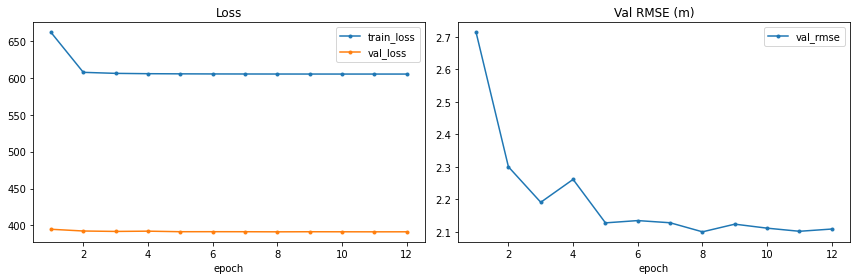

In [5]:
t0 = time.time()
training_log = fit(model, train_s, val_s, centers, save_dir=str(CKPT_DIR), **HPARAMS)
train_minutes = (time.time() - t0) / 60

log_df = pd.DataFrame(training_log)
display(log_df)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
log_df.plot(x="epoch", y=["train_loss", "val_loss"], marker=".", ax=axes[0], title="Loss")
log_df.plot(x="epoch", y="val_rmse", marker=".", ax=axes[1], title="Val RMSE (m)")
plt.tight_layout(); plt.show()

## 6. Evaluate (best checkpoint) — RMSE 1s…5s overall, per site, zero-neighbour scenes

**Decisions in this cell:** RMSE of the predicted mean at 1-5 s on the test split, overall / per site / target-only scenes (S7).

In [6]:
model.load_state_dict(torch.load(CKPT_DIR / "best_model.pt", map_location=DEVICE, weights_only=True))
model.eval()
test_s = normalize_samples(test_raw, norm_stats)

test_metrics = {}
for label, samples in test_groups(test_s).items():
    dl = create_dataloader(samples, batch_size=32, shuffle=False)
    test_metrics[label] = {**evaluate_trajectory(model, dl, DEVICE), "n": len(samples)}
display(pd.DataFrame(test_metrics).T)

,rmse_1s,rmse_2s,rmse_3s,rmse_4s,rmse_5s,rmse_avg,n
NGSIM Test Split,0.478174,1.147696,1.958409,2.961651,4.181377,2.145462,121130.0
site us-101,0.452204,1.104947,1.927182,2.974350,4.266863,2.145109,62135.0
zero-neighbour samples,0.570961,1.355746,2.320090,3.509876,4.947935,2.540922,3120.0
site i-80,0.504081,1.191064,1.990767,2.948218,4.089410,2.144708,58995.0


## 7. Collision prediction (optional)
Model's predicted target vs constant-velocity neighbours, every risk metric at its default threshold.

**Decisions in this cell:** neighbours are rolled forward at constant velocity and candidates are the nearest vehicles at the last history step, as in `--mode collisions`; only the target trajectory comes from this model.

In [7]:
collisions = None
if RUN_COLLISIONS:
    scores, gt, _ = collision_scores(model, loader, test_raw, norm_stats, COLLISION_THRESHOLD)
    collisions = {"threshold": COLLISION_THRESHOLD, "n_pairs": len(gt),
                  "n_gt_collisions": int(gt.sum()), "rows": metric_rows(scores, gt)}
    print(f"{len(gt)} pairs, {int(gt.sum())} GT collisions")
    display(pd.DataFrame(collisions["rows"]).set_index("metric"))

## 8. Save result

**Decisions in this cell:** one JSON per `EXP_NAME`; a rerun overwrites it.

In [8]:
save_result({
    "name": EXP_NAME,
    "description": DESCRIPTION,
    "model_class": type(model).__name__,
    "n_params": n_params,
    "hparams": HPARAMS,
    "data": {"locations": LOCATIONS, "debug": DEBUG},
    "train_minutes": train_minutes,
    "training_log": training_log,
    "test": test_metrics,
    "collisions": collisions,
})

Saved /home/st_students/MTP/experiments/results/fhif.json


PosixPath('/home/st_students/MTP/experiments/results/fhif.json')

## 9. Comparison & benchmarking — all results in `experiments/results/`

Ranked by overall test `rmse_avg` (best per column highlighted). Check the `data` column:
debug and full-data runs are listed together but are not comparable.
Also written to `experiments/comparison_rmse.csv` / `comparison_collisions.csv`.

**Decisions in this cell:** compares every saved result; only rows with the same `data` value are like-for-like.

,description,data,epochs,n_params,rmse_1s,rmse_2s,rmse_3s,rmse_4s,rmse_5s,rmse_avg,site us-101 avg,zero-neighbour samples avg,site i-80 avg
model,,,,,,,,,,,,,
dacr_amtp,"LOOSE: per-step dynamic attention + GRU context reasoning, 6 multimodal queries","us-101,i-80",12,254150,0.4603,1.1221,1.9212,2.9094,4.1144,2.1055,2.0954,2.4974,2.1150
cognitive,"Cognitive-driven: safety (TTC/TET/TIT) + behaviour centrality + priority attention, Leanformer fusion","us-101,i-80",12,227979,0.4624,1.1204,1.9247,2.9255,4.1366,2.1139,2.0999,2.5102,2.1276
fhif,LOOSE: individual / pairwise / group interaction features fused hierarchically with gates,"us-101,i-80",12,171141,0.4782,1.1477,1.9584,2.9617,4.1814,2.1455,2.1451,2.5409,2.1447
cf_lstm,"LOOSE: cascaded LSTMs (vehicle states, then target + per-step pooled interaction)","us-101,i-80",12,175109,0.4755,1.1638,2.0026,3.0541,4.3407,2.2073,2.2001,2.5426,2.2135
cs_lstm,CS-LSTM: LSTM encoders + 13x3 convolutional social pooling (unimodal),"us-101,i-80",12,192117,0.4738,1.1644,2.0267,3.1300,4.5015,2.2593,2.2737,2.5803,2.2420
bat,"BAT-style: centrality behaviour features + polar pooling + priority attention, 9 latent manoeuvres","us-101,i-80",12,152015,0.5486,1.2622,2.1246,3.1774,4.4043,2.3034,2.3297,4.3391,2.2746
cdstraj,CDSTraj-style: spatial-temporal interaction encoder + full-trajectory diffusion with a cross-attention transformer denoiser,"us-101,i-80",12,210492,1.1403,1.7166,2.6281,3.8572,5.2860,2.9256,2.9225,3.3681,2.9311
cv,"Constant velocity: last speed rolled forward, no training","us-101,i-80",0,0,0.6021,1.5879,2.8777,4.4704,6.3260,3.1728,3.3161,3.2966,3.0112
c2f_tp,C2F-TP-style: multimodal coarse predictor + conditional diffusion refinement (DDIM),"us-101,i-80",12,475334,5.1482,6.2205,5.8009,7.9724,6.7000,6.3684,6.2802,6.5804,6.4683


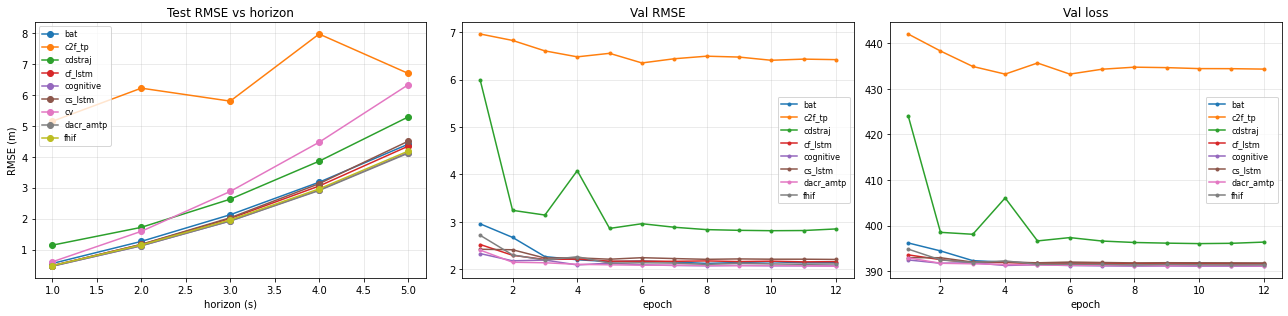

In [9]:
rmse_df, collision_df = compare()